## Loading the Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train = pd.read_csv("../data/train_test.csv")
val = pd.read_csv("../data/validation.csv")
dec = pd.read_csv("../data/december_chart_inputs.csv")
print(train.shape, val.shape, dec.shape)
train.head()

(48000, 14) (12000, 13) (31, 7)


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [2]:
print("train dates:", train["date"].min(), "to", train["date"].max())
print("val dates:  ", val["date"].min(), "to", val["date"].max())

print("\nmissing values in train:")
print(train.isna().sum()[train.isna().sum() > 0])
print("\nmissing values in val:")
print(val.isna().sum()[val.isna().sum() > 0])

train dates: 2025-01-01 to 2025-10-31
val dates:   2025-11-01 to 2025-12-31

missing values in train:
weight          300
market_index    374
dtype: int64

missing values in val:
weight          165
market_index    249
dtype: int64


In [3]:
print(train["equipment"].value_counts())

train_cities = set(train["pickup"]) | set(train["delivery"])
val_cities = set(val["pickup"]) | set(val["delivery"])
new_cities = val_cities - train_cities
print("\ncities only in validation:", new_cities)

n_new = (val["pickup"].isin(new_cities) | val["delivery"].isin(new_cities)).sum()
print("val rows touching a new city:", n_new)

equipment
Dry Van    27202
Reefer     12045
Flatbed     8753
Name: count, dtype: int64

cities only in validation: {'Jackson', 'Allentown', 'Laredo', 'Knoxville', 'San Diego', 'Norfolk', 'Charlotte', 'Chicago'}
val rows touching a new city: 1447


In [4]:
print(train["weight"].describe())
print("\nnegative weights:", (train["weight"] < 0).sum())
print("weight exactly 47500:", (train["weight"] == 47500).sum())

count    47700.000000
mean     31028.844004
std       9391.440620
min     -47500.000000
25%      25800.000000
50%      31436.500000
75%      37018.000000
max      47500.000000
Name: weight, dtype: float64

negative weights: 292
weight exactly 47500: 1191


## Checking distances against coordinates
Road distance is usually ~1.18x the straight line, so anything above 1.6x is suspicious.

In [5]:
def straight_line_miles(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 3958.8 * 2 * np.arcsin(np.sqrt(a))

for df in [train, val]:
    df["straight_miles"] = straight_line_miles(df["pickup_lat"], df["pickup_lon"],
                                               df["delivery_lat"], df["delivery_lon"])
    df["road_ratio"] = df["distance"] / df["straight_miles"]

print(train["road_ratio"].describe())
print("\nrows where distance looks too long (ratio > 1.6):")
print("train:", (train["road_ratio"] > 1.6).sum(), " val:", (val["road_ratio"] > 1.6).sum())

count    48000.000000
mean         1.194681
std          0.143541
min          1.058090
25%          1.164765
50%          1.182231
75%          1.204765
max          9.634919
Name: road_ratio, dtype: float64

rows where distance looks too long (ratio > 1.6):
train: 111  val: 34


In [6]:
train["rate_per_mile"] = train["posted_rate"] / train["distance"]
print(train["rate_per_mile"].describe())

lane_median = train.groupby(["pickup", "delivery", "equipment"])["rate_per_mile"].transform("median")
train["vs_lane"] = train["rate_per_mile"] / lane_median

print("\nprice more than 2x its usual lane price:", (train["vs_lane"] > 2).sum())
print("price less than half its usual lane price:", (train["vs_lane"] < 0.5).sum())
train[train["vs_lane"] > 2][["pickup", "delivery", "distance", "equipment", "posted_rate", "vs_lane"]].head()

count    48000.000000
mean         2.215347
std          0.583887
min          0.333709
25%          1.986974
50%          2.145348
75%          2.342696
max         14.125294
Name: rate_per_mile, dtype: float64

price more than 2x its usual lane price: 303
price less than half its usual lane price: 325


,pickup,delivery,distance,equipment,posted_rate,vs_lane
469,Phoenix,Jacksonville,2154.3,Dry Van,10854.69,2.622431
785,Kansas City,Charleston,861.5,Dry Van,4587.83,2.521870
870,Tulsa,Baton Rouge,305.6,Reefer,4069.24,4.677205
1149,Houston,Baton Rouge,170.3,Flatbed,1359.60,2.627363
1175,Tucson,Phoenix,260.5,Dry Van,1609.22,2.591974


       rate_per_mile  market_index
month                             
1              2.029         0.927
2              2.061         0.996
3              2.139         1.073
4              2.147         1.208
5              2.190         1.301
6              2.248         1.280
7              2.187         1.201
8              2.121         0.981
9              2.160         0.893
10             2.164         0.958


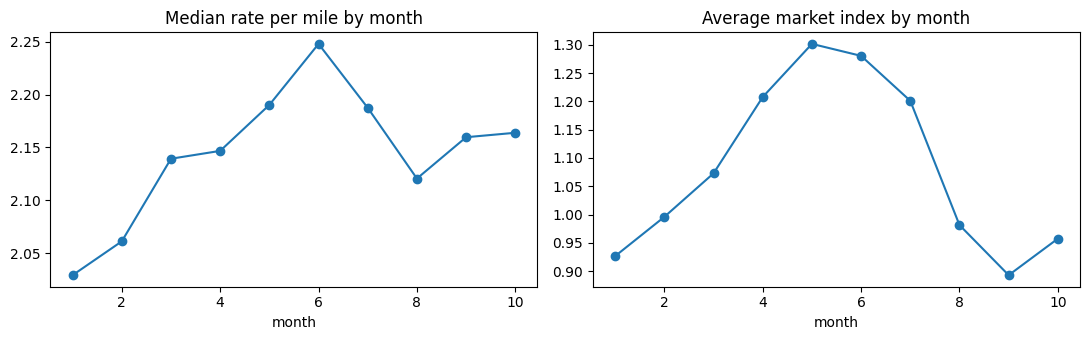

In [7]:
train["month"] = pd.to_datetime(train["date"]).dt.month
monthly = train.groupby("month").agg(rate_per_mile=("rate_per_mile", "median"),
                                     market_index=("market_index", "mean"))
print(monthly.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
monthly["rate_per_mile"].plot(ax=ax[0], marker="o", title="Median rate per mile by month")
monthly["market_index"].plot(ax=ax[1], marker="o", title="Average market index by month")
plt.tight_layout()
plt.show()

In [8]:
print(dec.columns.tolist())

['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']


**Exploration Summary** <br>
We will clean the dataset by fixing missing values, negative weights, and invalid prices. Distances looked suspicious on some short routes but turned out to be consistent, so we left them unchanged. We’ll use a time-based split since we’re predicting future months, handle new cities using coordinates instead of city names, and fill December’s missing inputs (coordinates and market index) from the other files.

## Cleaning

In [9]:
# city -> coordinates (needed for December, which has no lat/lon)
city_coords = pd.concat([
    train[["pickup", "pickup_lat", "pickup_lon"]].set_axis(["city", "lat", "lon"], axis=1),
    train[["delivery", "delivery_lat", "delivery_lon"]].set_axis(["city", "lat", "lon"], axis=1),
    val[["pickup", "pickup_lat", "pickup_lon"]].set_axis(["city", "lat", "lon"], axis=1),
    val[["delivery", "delivery_lat", "delivery_lon"]].set_axis(["city", "lat", "lon"], axis=1),
]).drop_duplicates("city").set_index("city")

# market index is basically one value per day, so average it per date
daily_index = pd.concat([train, val]).groupby("date")["market_index"].mean()

weight_median = train.loc[train["weight"] > 0].groupby("equipment")["weight"].median()

print(len(city_coords), "cities,", len(daily_index), "days of market index")
print(weight_median)

72 cities, 365 days of market index
equipment
Dry Van    31442.5
Flatbed    31525.0
Reefer     31576.5
Name: weight, dtype: float64


In [10]:
def clean(df):
    df = df.copy()
    df["weight"] = df["weight"].abs()  # negative weights look like sign errors
    df["weight"] = df["weight"].fillna(df["equipment"].map(weight_median))
    df["market_index"] = df["market_index"].fillna(df["date"].map(daily_index))
    return df

train_clean = clean(train)
val_clean = clean(val)
print("missing left:", train_clean.isna().sum().sum(), val_clean.isna().sum().sum())

missing left: 0 0


In [11]:
train_clean["rate_per_mile"] = train_clean["posted_rate"] / train_clean["distance"]
lane_median = train_clean.groupby(["pickup", "delivery"])["rate_per_mile"].transform("median")
ratio = train_clean["rate_per_mile"] / lane_median

bad_price = (ratio > 2) | (ratio < 0.5)
train_clean = train_clean[~bad_price].drop(columns="rate_per_mile").reset_index(drop=True)
print("removed", bad_price.sum(), "rows, left with", len(train_clean))

removed 672 rows, left with 47328


In [12]:
dec_clean = dec.copy()
for side in ["pickup", "delivery"]:
    dec_clean[side + "_lat"] = dec_clean[side].map(city_coords["lat"])
    dec_clean[side + "_lon"] = dec_clean[side].map(city_coords["lon"])
dec_clean["market_index"] = dec_clean["date"].map(daily_index)
dec_clean.head()

,pickup,delivery,distance,equipment,weight,date,predicted_rate,pickup_lat,pickup_lon,delivery_lat,delivery_lon,market_index
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,NaN,36.99152,-84.99876,41.31561,-85.36206,0.834919
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,NaN,36.99152,-84.99876,41.31561,-85.36206,0.914680
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,NaN,36.99152,-84.99876,41.31561,-85.36206,0.994063
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,NaN,36.99152,-84.99876,41.31561,-85.36206,1.024021
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,NaN,36.99152,-84.99876,41.31561,-85.36206,0.975120


**Cleaning Summary** <br>
Flipped 292 negative weights, filled missing weight with the median per equipment and missing market_index with that day’s average. Removed 672 rows (1.4%) with prices over 2x or under 0.5x their route’s typical rate per mile. Distances left unchanged. Prepared December with coordinates from a city lookup and that day’s market index.

## Validation split

In [13]:
train_clean["date"] = pd.to_datetime(train_clean["date"])

# validation is Nov-Dec, so hold out the last two months of training to mimic that
fit = train_clean[train_clean["date"] < "2025-09-01"]
test = train_clean[train_clean["date"] >= "2025-09-01"]

print("fit: ", fit["date"].min().date(), "to", fit["date"].max().date(), len(fit), "rows")
print("test:", test["date"].min().date(), "to", test["date"].max().date(), len(test), "rows")

fit:  2025-01-01 to 2025-08-31 37949 rows
test: 2025-09-01 to 2025-10-31 9379 rows


**Split Summary** <br>
Validation covers Nov–Dec 2025, which the model never sees, so I held out the last two months of training (Sep–Oct, 9,379 rows) as a test set and trained on Jan–Aug (37,949 rows).

## Baselines

In [14]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

results = []

def score(name, pred):
    mae = mean_absolute_error(test["posted_rate"], pred)
    mape = mean_absolute_percentage_error(test["posted_rate"], pred) * 100
    results.append({"model": name, "MAE ($)": round(mae, 1), "MAPE (%)": round(mape, 2)})
    print(f"{name}: MAE ${mae:.0f}, MAPE {mape:.2f}%")

fit_rpm = fit["posted_rate"] / fit["distance"]
score("Overall median rate/mile", fit_rpm.median() * test["distance"])

equip_rpm = fit_rpm.groupby(fit["equipment"]).median()
score("Median rate/mile per equipment", test["equipment"].map(equip_rpm) * test["distance"])

Overall median rate/mile: MAE $204, MAPE 9.27%
Median rate/mile per equipment: MAE $175, MAPE 8.09%


In [15]:
from sklearn.linear_model import LinearRegression

def linear_features(df):
    X = pd.DataFrame({
        "log_distance": np.log(df["distance"]),
        "weight": df["weight"],
        "market_index": df["market_index"],
    })
    return X.join(pd.get_dummies(df["equipment"], dtype=float))

lin = LinearRegression().fit(linear_features(fit), np.log(fit["posted_rate"]))
score("Linear regression", np.exp(lin.predict(linear_features(test))))

pd.DataFrame(results)

Linear regression: MAE $111, MAPE 4.66%


,model,MAE ($),MAPE (%)
0,Overall median rate/mile,203.7,9.27
1,Median rate/mile per equipment,175.1,8.09
2,Linear regression,110.8,4.66


**Baseline Summmary** <br>
The simplest guess (distance × median rate per mile) is off by 9.27% on average. Using a separate rate per equipment type brings it to 8.09%, and linear regression to 4.66%. The main model needs to beat 4.66% to be worth using.

## Gradient boosting model

In [16]:
from sklearn.ensemble import HistGradientBoostingRegressor

FEATURES = ["distance", "weight", "equipment", "pickup_lat", "pickup_lon",
            "delivery_lat", "delivery_lon", "market_index", "quote_signal"]

def make_features(df, features):
    X = df[features].copy()
    X["equipment"] = X["equipment"].map({"Dry Van": 0, "Reefer": 1, "Flatbed": 2})
    return X

def train_model(df, features):
    model = HistGradientBoostingRegressor(max_iter=600, learning_rate=0.05,
                                          categorical_features=[features.index("equipment")],
                                          random_state=42)
    # predict rate per mile, then multiply back by distance
    model.fit(make_features(df, features), df["posted_rate"] / df["distance"])
    return model

def predict(model, df, features):
    return model.predict(make_features(df, features)) * df["distance"].values

model = train_model(fit, FEATURES)
score("Gradient boosting", predict(model, test, FEATURES))

Gradient boosting: MAE $74, MAPE 2.99%


In [17]:
FEATURES_NO_QUOTE = [f for f in FEATURES if f != "quote_signal"]
model_nq = train_model(fit, FEATURES_NO_QUOTE)
score("Gradient boosting (no quote_signal)", predict(model_nq, test, FEATURES_NO_QUOTE))

Gradient boosting (no quote_signal): MAE $105, MAPE 4.38%


In [18]:
fit_dow, test_dow = fit.copy(), test.copy()
for df in [fit_dow, test_dow]:
    df["day_of_week"] = df["date"].dt.dayofweek

model_dow = train_model(fit_dow, FEATURES + ["day_of_week"])
score("Gradient boosting + day_of_week", predict(model_dow, test_dow, FEATURES + ["day_of_week"]))

Gradient boosting + day_of_week: MAE $80, MAPE 3.21%


In [19]:
import random

cities = sorted(set(fit["pickup"]) | set(fit["delivery"]))
random.seed(1)
hidden = set(random.sample(cities, 8))

fit_seen = fit[~(fit["pickup"].isin(hidden) | fit["delivery"].isin(hidden))]
test_new = test[test["pickup"].isin(hidden) | test["delivery"].isin(hidden)]

m = train_model(fit_seen, FEATURES)
p = predict(m, test_new, FEATURES)
print("MAPE on routes with cities the model never saw:",
      round(mean_absolute_percentage_error(test_new["posted_rate"], p) * 100, 2), "%")

MAPE on routes with cities the model never saw: 3.06 %


In [20]:
pd.DataFrame(results)

,model,MAE ($),MAPE (%)
0,Overall median rate/mile,203.7,9.27
1,Median rate/mile per equipment,175.1,8.09
2,Linear regression,110.8,4.66
3,Gradient boosting,74.1,2.99
4,Gradient boosting (no quote_signal),105.1,4.38
5,Gradient boosting + day_of_week,80.0,3.21


**Model Summary** <br>
I tested both Linear Regression and Gradient Boosting, and Gradient Boosting performed better, with a 2.99% MAPE compared to 4.66% for Linear Regression. The model predicts rate per mile, which is then multiplied by distance to get the price. I also found that adding `quote_signal` improved the results, since the error increased to 4.38% without it. So I used it for validation but not for December, since it's not available there. Adding the day of the week made it slightly worse (3.21%), so I left it out. I also tested the model by hiding 8 cities, and the error only increased slightly to 3.06%, which shows that the model can handle new cities quite well.

## December predictions

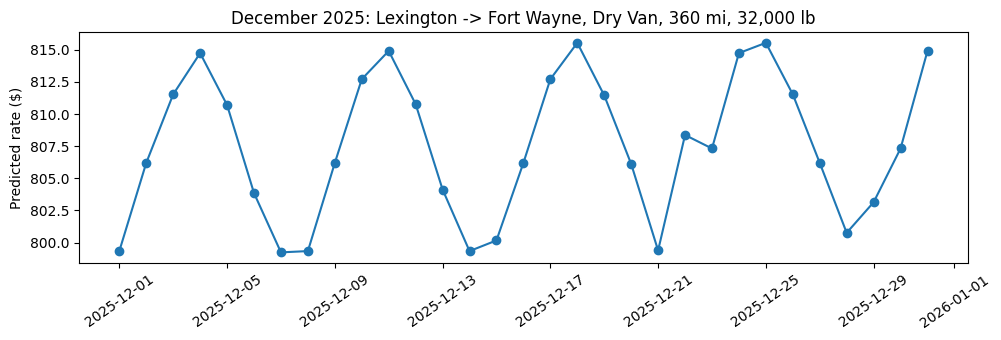

range: 799.24 to 815.54


In [21]:
# December has no quote_signal, so use the model without it, trained on all cleaned data
dec_model = train_model(train_clean, FEATURES_NO_QUOTE)
dec_clean["predicted_rate"] = predict(dec_model, dec_clean, FEATURES_NO_QUOTE).round(2)

plt.figure(figsize=(10, 3.5))
plt.plot(pd.to_datetime(dec_clean["date"]), dec_clean["predicted_rate"], marker="o")
plt.title("December 2025: Lexington -> Fort Wayne, Dry Van, 360 mi, 32,000 lb")
plt.ylabel("Predicted rate ($)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

print("range:", dec_clean["predicted_rate"].min(), "to", dec_clean["predicted_rate"].max())

In [22]:
history = train_clean[(train_clean["pickup"] == "Lexington") &
                      (train_clean["delivery"] == "Fort Wayne") &
                      (train_clean["equipment"] == "Dry Van")]
print(len(history), "past Dry Van loads on this route")
print(history["posted_rate"].describe().round(1))

21 past Dry Van loads on this route
count     21.0
mean     823.3
std       46.2
min      757.9
25%      791.2
50%      807.9
75%      849.2
max      934.4
Name: posted_rate, dtype: float64


**December Summary** <br>
For December, I used the model trained on cleaned Jan–Oct data without `quote_signal`, since it wasn't available. The predicted prices range from $799.24 to $815.54, which is close to the historical median of $807.90. Prices change smoothly based on the daily market index, with slightly lower prices on weekends and higher prices mid-week, without any unusual jumps.